In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/encounters_features.csv", low_memory=False)

data = df[df["is_first_encounter"] == 1].reset_index(drop=True)
print("Patients:", len(data), "| readmission rate:", round(data["readmitted_30d"].mean() * 100, 2), "%")

Patients: 69987 | readmission rate: 8.98 %


In [2]:
numeric_features = ["age_years", "time_in_hospital", "num_lab_procedures", "num_procedures",
                    "num_medications", "number_outpatient", "number_emergency", "number_inpatient",
                    "total_prior_visits", "number_diagnoses", "a1c_tested", "a1c_high",
                    "n_diabetes_meds", "n_med_changes", "on_insulin", "med_changed", "on_diabetes_med"]

categorical_features = ["gender", "admission_type", "admission_source", "discharge_group",
                        "specialty_group", "payer_code", "primary_diagnosis", "diag_2_group",
                        "diag_3_group", "max_glu_serum"]

X = data[numeric_features + categorical_features]
y = data["readmitted_30d"]
X.shape

(69987, 27)

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train:", X_train.shape, "| rate", round(y_train.mean() * 100, 2), "%")
print("Test: ", X_test.shape, "| rate", round(y_test.mean() * 100, 2), "%")

Train: (55989, 27) | rate 8.98 %
Test:  (13998, 27) | rate 8.98 %


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

def make_preprocessor(scale):
    return ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50, sparse_output=False),
         categorical_features),
    ])

models = {
    "Logistic Regression": Pipeline([
        ("prep", make_preprocessor(scale=True)),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced", C=0.5))]),
    "Random Forest": Pipeline([
        ("prep", make_preprocessor(scale=False)),
        ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=25, max_features=0.3,
                                         class_weight="balanced_subsample", n_jobs=-1, random_state=42))]),
    "Gradient Boosting": Pipeline([
        ("prep", make_preprocessor(scale=False)),
        ("model", HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_leaf_nodes=15,
                                                 min_samples_leaf=50, l2_regularization=1.0,
                                                 class_weight="balanced", random_state=42))]),
}

In [5]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for name, pipe in models.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["roc_auc", "average_precision"])
    rows.append({"model": name,
                 "cv_roc_auc": scores["test_roc_auc"].mean().round(3),
                 "cv_pr_auc": scores["test_average_precision"].mean().round(3)})

results = pd.DataFrame(rows)
results

,model,cv_roc_auc,cv_pr_auc
0,Logistic Regression,0.644,0.161
1,Random Forest,0.653,0.177
2,Gradient Boosting,0.650,0.172


In [7]:
from sklearn.metrics import roc_auc_score, average_precision_score

test_scores = {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    test_scores[name] = pipe.predict_proba(X_test)[:, 1]

results["test_roc_auc"] = [round(roc_auc_score(y_test, test_scores[m]), 3) for m in results["model"]]
results["test_pr_auc"]  = [round(average_precision_score(y_test, test_scores[m]), 3) for m in results["model"]]
print(results)
print("Coin-flip PR-AUC:", round(y_test.mean(), 3))

best_name = "Random Forest"
best_model = models[best_name]
score = test_scores[best_name]

                 model  cv_roc_auc  cv_pr_auc  test_roc_auc  test_pr_auc
0  Logistic Regression       0.644      0.161         0.646        0.160
1        Random Forest       0.653      0.177         0.661        0.178
2    Gradient Boosting       0.650      0.172         0.659        0.170
Coin-flip PR-AUC: 0.09


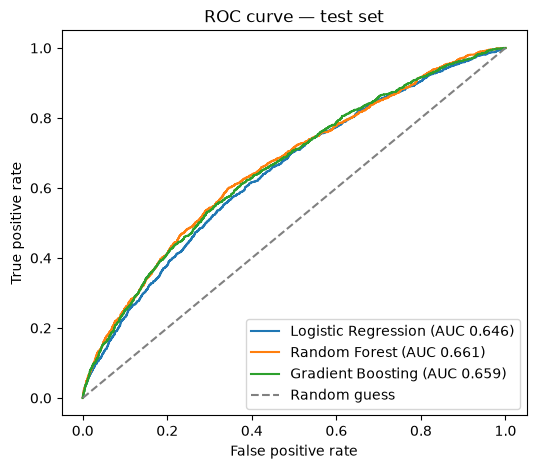

In [8]:
import os
from sklearn.metrics import roc_curve
os.makedirs("../outputs/figures", exist_ok=True)

plt.figure(figsize=(6, 5))
for name, s in test_scores.items():
    fpr, tpr, _ = roc_curve(y_test, s)
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, s):.3f})")
plt.plot([0, 1], [0, 1], "--", color="grey", label="Random guess")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curve — test set"); plt.legend()
plt.savefig("../outputs/figures/roc_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
d = pd.DataFrame({"actual": y_test.values, "risk_score": score}).sort_values("risk_score", ascending=False)
d["risk_decile"] = np.arange(len(d)) * 10 // len(d) + 1

deciles = d.groupby("risk_decile").agg(patients=("actual", "size"), readmissions=("actual", "sum")).reset_index()
deciles["readmit_rate_pct"] = (100 * deciles["readmissions"] / deciles["patients"]).round(1)
deciles["lift"] = (deciles["readmit_rate_pct"] / (100 * y_test.mean())).round(2)
deciles["cum_capture_pct"] = (100 * deciles["readmissions"].cumsum() / deciles["readmissions"].sum()).round(1)
deciles

,risk_decile,patients,readmissions,readmit_rate_pct,lift,cum_capture_pct
0,1,1400,288,20.6,2.29,22.9
1,2,1400,201,14.4,1.60,38.9
2,3,1400,157,11.2,1.25,51.4
3,4,1400,136,9.7,1.08,62.2
4,5,1399,96,6.9,0.77,69.8
5,6,1400,81,5.8,0.65,76.3
6,7,1400,95,6.8,0.76,83.9
7,8,1400,84,6.0,0.67,90.5
8,9,1400,81,5.8,0.65,97.0
9,10,1399,38,2.7,0.30,100.0


In [10]:
test_rows = data.loc[X_test.index]
rule = ((test_rows["number_inpatient"] >= 2) |
        test_rows["discharge_group"].isin(["Skilled nursing facility", "Rehab / long-term care"])).values

share = rule.mean()
model_flag = score >= np.quantile(score, 1 - share)

print(f"Both flag {share:.1%} of patients")
print(f"Rule  catches {100 * y_test[rule].sum() / y_test.sum():.1f}% of readmissions")
print(f"Model catches {100 * y_test[model_flag].sum() / y_test.sum():.1f}% of readmissions")

Both flag 19.3% of patients
Rule  catches 34.2% of readmissions
Model catches 37.7% of readmissions


In [11]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(best_model, X_test, y_test, scoring="average_precision",
                              n_repeats=5, random_state=42)
importance = (pd.DataFrame({"feature": X_test.columns, "importance": perm.importances_mean})
              .sort_values("importance", ascending=False).round(4))
importance.head(10)

,feature,importance
20,discharge_group,0.0607
7,number_inpatient,0.0149
22,payer_code,0.0080
8,total_prior_visits,0.0069
9,number_diagnoses,0.0060
23,primary_diagnosis,0.0046
2,num_lab_procedures,0.0040
21,specialty_group,0.0035
18,admission_type,0.0028
1,time_in_hospital,0.0027


In [12]:
scored = test_rows.copy()
scored["risk_score"] = score.round(4)
scored.to_csv("../data/processed/test_patients_scored.csv", index=False)
scored.shape

(13998, 40)